# S&P 500 데이터 정제와 분석

pandas를 사용해 원본 CSV를 점검·정리하고, 종가 추이와 수익률·변동성·연도별 및 월별 통계를 살펴봅니다. 원본 파일은 `S&P 500 과거 데이터.csv`이며, 데이터의 실제 기간은 **2000-01-03부터 2019-11-14까지**입니다. 따라서 2019년 12월 데이터는 포함되어 있지 않습니다.

## 1. 라이브러리와 원본 데이터 확인

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("S&P 500 과거 데이터.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV 파일을 찾을 수 없습니다: {DATA_PATH.resolve()}")

df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
print(f"원본 크기: {df_raw.shape[0]:,}행 × {df_raw.shape[1]}열")
print("열 이름:", df_raw.columns.tolist())
display(df_raw.head())
display(df_raw.info())

원본 크기: 5,000행 × 7열
열 이름: ['날짜', '종가', '시가', '고가', '저가', '거래량', '변동 %']


,날짜,종가,시가,고가,저가,거래량,변동 %
0,2019- 11- 14,"3,096.60","3,090.80","3,098.20","3,083.30",NaN,0.08%
1,2019- 11- 13,"3,094.00","3,084.20","3,098.10","3,078.80",NaN,0.07%
2,2019- 11- 12,"3,091.80","3,089.30","3,102.60","3,084.70",NaN,0.16%
3,2019- 11- 11,"3,087.00","3,080.30","3,088.30","3,075.80",NaN,-0.20%
4,2019- 11- 08,"3,093.10","3,081.20","3,093.10","3,073.60",NaN,0.26%


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   날짜      5000 non-null   str    
 1   종가      5000 non-null   str    
 2   시가      5000 non-null   str    
 3   고가      5000 non-null   str    
 4   저가      5000 non-null   str    
 5   거래량     0 non-null      float64
 6   변동 %    5000 non-null   str    
dtypes: float64(1), str(6)
memory usage: 273.6 KB


None

## 2. 데이터 클렌징

날짜의 공백을 제거해 날짜형으로 바꾸고, 가격의 천 단위 쉼표 및 변동률의 `%` 기호를 제거해 숫자로 변환합니다. 값이 전부 비어 있는 거래량 열은 제거합니다. 날짜 또는 종가가 유효하지 않은 행은 분석에 사용할 수 없어 제외하며, 같은 날짜가 중복되면 첫 행만 남깁니다. 가격의 다른 열에 결측이 있다면 종가 분석을 위해 행 전체를 버리지 않고 결측 현황을 별도로 확인합니다.

In [2]:
df = df_raw.copy()
df.columns = df.columns.str.strip()

if "날짜" not in df.columns:
    raise KeyError("원본에서 '날짜' 열을 찾을 수 없습니다.")

df["날짜"] = pd.to_datetime(
    df["날짜"].astype("string").str.replace(" ", "", regex=False),
    format="%Y-%m-%d",
    errors="coerce",
)

price_columns = [column for column in ["종가", "시가", "고가", "저가"] if column in df.columns]
for column in price_columns:
    df[column] = pd.to_numeric(
        df[column].astype("string").str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    )

if "변동 %" in df.columns:
    df["변동 %"] = pd.to_numeric(
        df["변동 %"].astype("string").str.replace("%", "", regex=False).str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    ) / 100

empty_columns = [column for column in df.columns if df[column].isna().all()]
df = df.drop(columns=empty_columns)

before_rows = len(df)
df = df.dropna(subset=["날짜", "종가"])
invalid_rows_removed = before_rows - len(df)
duplicate_dates = int(df.duplicated(subset=["날짜"]).sum())
df = df.drop_duplicates(subset=["날짜"], keep="first")
df = df.sort_values("날짜").reset_index(drop=True)

print("제거한 완전 결측 열:", empty_columns if empty_columns else "없음")
print(f"날짜/종가 오류로 제거한 행: {invalid_rows_removed:,}행")
print(f"중복 날짜 제거: {duplicate_dates:,}행")
print(f"정제 후 크기: {len(df):,}행 × {df.shape[1]}열")
print(f"분석 기간: {df['날짜'].min():%Y-%m-%d} ~ {df['날짜'].max():%Y-%m-%d}")
display(df.head())
display(df.tail())

제거한 완전 결측 열: ['거래량']
날짜/종가 오류로 제거한 행: 0행
중복 날짜 제거: 0행
정제 후 크기: 5,000행 × 6열
분석 기간: 2000-01-03 ~ 2019-11-14


,날짜,종가,시가,고가,저가,변동 %
0,2000-01-03,1455.2,1469.2,1478.0,1438.4,-0.0095
1,2000-01-04,1399.4,1455.2,1455.2,1397.4,-0.0383
2,2000-01-05,1402.1,1399.4,1413.3,1377.7,0.0019
3,2000-01-06,1403.5,1402.1,1411.9,1392.0,0.001
4,2000-01-07,1441.5,1403.5,1441.5,1400.5,0.0271


,날짜,종가,시가,고가,저가,변동 %
4995,2019-11-08,3093.1,3081.2,3093.1,3073.6,0.0026
4996,2019-11-11,3087.0,3080.3,3088.3,3075.8,-0.002
4997,2019-11-12,3091.8,3089.3,3102.6,3084.7,0.0016
4998,2019-11-13,3094.0,3084.2,3098.1,3078.8,0.0007
4999,2019-11-14,3096.6,3090.8,3098.2,3083.3,0.0008


## 3. 데이터 품질 및 기초 통계

정제된 데이터의 결측치, 수치형 변수의 요약 통계, 관측 기간을 확인합니다. 변동률 열은 퍼센트 수치를 소수로 환산했습니다(예: `0.08%` → `0.0008`).

In [3]:
print("결측치 개수:")
display(df.isna().sum().to_frame("결측치 수"))

print("수치형 열 요약 통계:")
display(df.select_dtypes(include="number").describe().T)

print(f"관측 일수: {len(df):,}")
print(f"관측 기간: {(df['날짜'].max() - df['날짜'].min()).days:,}일")

결측치 개수:


,결측치 수
날짜,0
종가,0
시가,0
고가,0
저가,0
변동 %,0


수치형 열 요약 통계:


,count,mean,std,min,25%,50%,75%,max
종가,5000.0,1565.18116,574.248865,676.5,1150.275,1358.2,1973.375,3096.6
시가,5000.0,1564.9905,574.162272,679.3,1150.45,1358.05,1974.275,3090.8
고가,5000.0,1573.89358,574.935851,695.3,1158.525,1366.95,1983.375,3102.6
저가,5000.0,1555.37556,573.241574,666.8,1140.95,1347.0,1965.15,3084.7
변동 %,5000.0,0.00022,0.01192,-0.0904,-0.0047,0.0005,0.0057,0.1159


관측 일수: 5,000
관측 기간: 7,255일


## 4. 종가 라인그래프

날짜를 오름차순으로 정렬한 종가 시계열입니다.

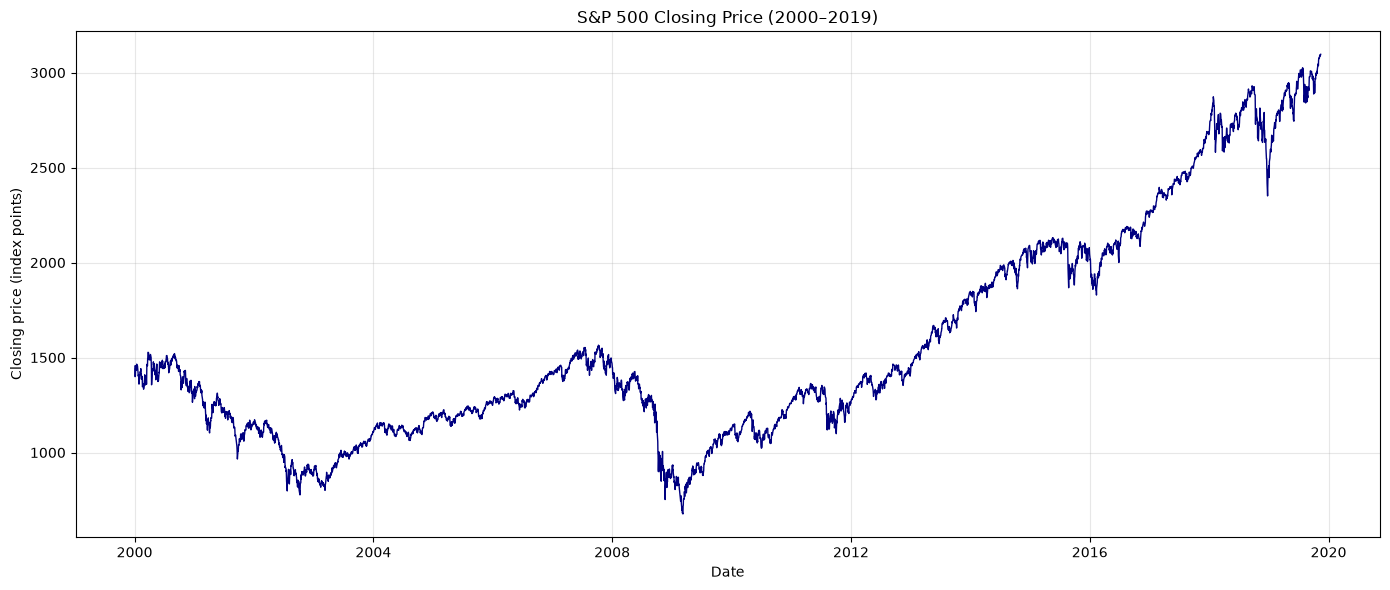

In [4]:
plt.figure(figsize=(14, 6))
plt.plot(df["날짜"], df["종가"], color="navy", linewidth=1)
plt.title("S&P 500 Closing Price (2000–2019)")
plt.xlabel("Date")
plt.ylabel("Closing price (index points)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. 일별 수익률과 위험 지표

종가 기준 일별 단순 수익률, 30거래일 이동평균, 누적 최고점 대비 낙폭(drawdown)을 계산합니다. 연율화 변동성은 일별 수익률 표준편차에 `√252`를 곱한 근사치입니다.

In [5]:
df["일별 수익률"] = df["종가"].pct_change(fill_method=None)
df["30일 이동평균"] = df["종가"].rolling(window=30, min_periods=30).mean()
df["누적 최고점"] = df["종가"].cummax()
df["고점 대비 낙폭"] = df["종가"] / df["누적 최고점"] - 1

daily_returns = df["일별 수익률"].dropna()
annualized_volatility = daily_returns.std() * (252 ** 0.5)
max_drawdown = df["고점 대비 낙폭"].min()

print(f"일별 수익률 평균: {daily_returns.mean():.4%}")
print(f"일별 수익률 표준편차: {daily_returns.std():.4%}")
print(f"연율화 변동성(252 거래일 기준): {annualized_volatility:.2%}")
print(f"최대 고점 대비 낙폭: {max_drawdown:.2%}")
display(df.loc[daily_returns.abs().nlargest(5).index, ["날짜", "종가", "일별 수익률"]].sort_values("날짜"))

일별 수익률 평균: 0.0222%
일별 수익률 표준편차: 1.1920%
연율화 변동성(252 거래일 기준): 18.92%
최대 고점 대비 낙폭: -56.78%


,날짜,종가,일별 수익률
2197,2008-09-29,1106.4,-0.087881
2207,2008-10-13,1003.4,0.115881
2209,2008-10-15,907.8,-0.090381
2218,2008-10-28,940.5,0.107904
2241,2008-12-01,816.2,-0.089266


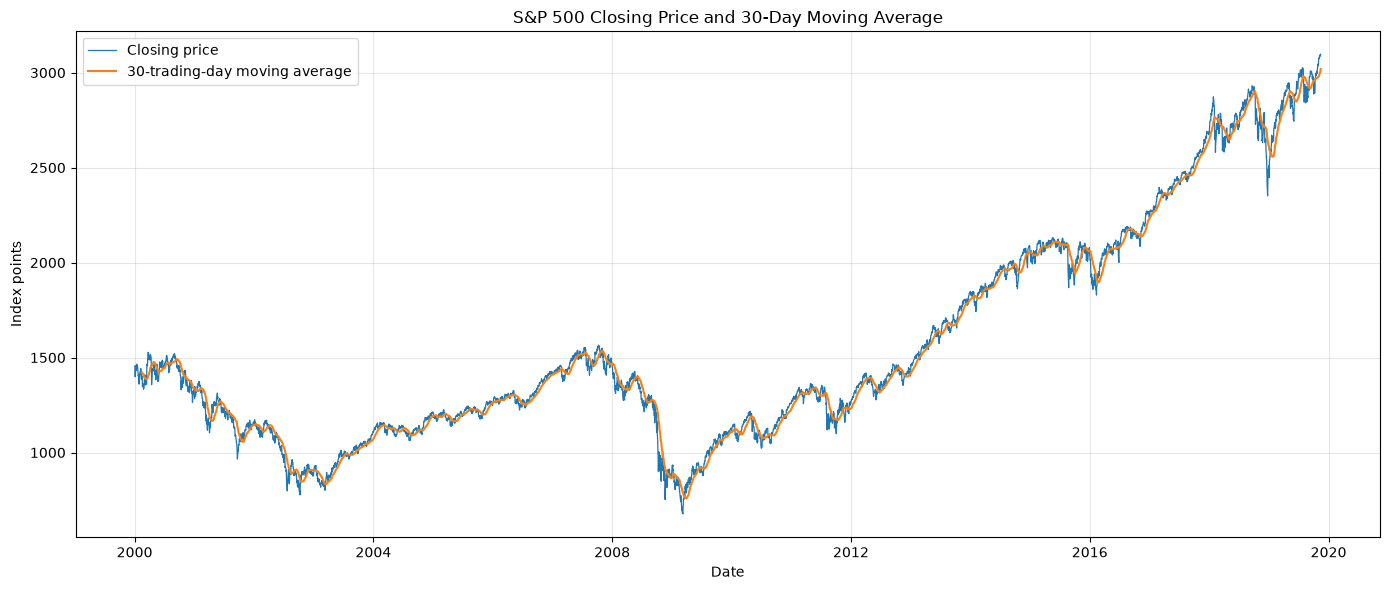

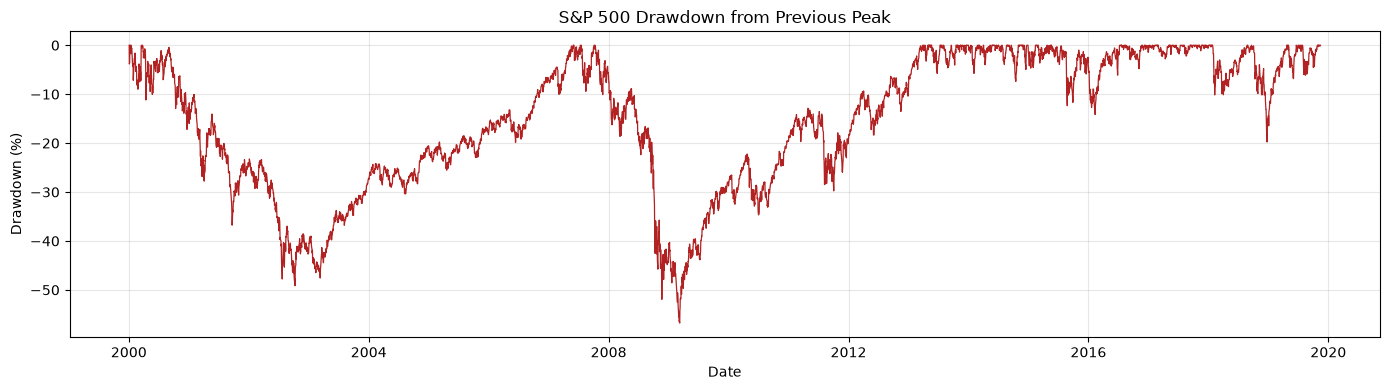

In [6]:
plt.figure(figsize=(14, 6))
plt.plot(df["날짜"], df["종가"], label="Closing price", linewidth=0.9)
plt.plot(df["날짜"], df["30일 이동평균"], label="30-trading-day moving average", linewidth=1.5)
plt.title("S&P 500 Closing Price and 30-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Index points")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 4))
plt.plot(df["날짜"], df["고점 대비 낙폭"] * 100, color="firebrick", linewidth=0.9)
plt.title("S&P 500 Drawdown from Previous Peak")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. 연도별 성과와 변동성

연도별 시가·종가·최고·최저 및 관측된 첫 종가 대비 마지막 종가 수익률을 계산합니다. 수익률은 각 연도의 첫 거래일 종가에서 마지막 거래일 종가까지의 변화이며, 연율화 변동성은 해당 연도의 일별 수익률로 추정합니다.

In [7]:
annual_groups = df.groupby(df["날짜"].dt.year)
annual_summary = annual_groups.agg(
    시작일=("날짜", "min"),
    종료일=("날짜", "max"),
    첫_종가=("종가", "first"),
    마지막_종가=("종가", "last"),
    평균_종가=("종가", "mean"),
    최고_종가=("종가", "max"),
    최저_종가=("종가", "min"),
    관측수=("종가", "count"),
)
annual_summary["연중 수익률"] = annual_summary["마지막_종가"] / annual_summary["첫_종가"] - 1
annual_summary["연율화 변동성"] = annual_groups["일별 수익률"].std() * (252 ** 0.5)
display(annual_summary.round({
    "첫_종가": 2, "마지막_종가": 2, "평균_종가": 2,
    "최고_종가": 2, "최저_종가": 2,
    "연중 수익률": 4, "연율화 변동성": 4,
}))

,시작일,종료일,첫_종가,마지막_종가,평균_종가,최고_종가,최저_종가,관측수,연중 수익률,연율화 변동성
날짜,,,,,,,,,,
2000,2000-01-03,2000-12-29,1455.2,1320.3,1427.22,1527.5,1264.7,252,-0.0927,0.2224
2001,2001-01-02,2001-12-31,1283.3,1148.1,1194.18,1373.7,965.8,248,-0.1054,0.2155
2002,2002-01-02,2002-12-31,1154.7,879.8,993.94,1172.5,776.8,252,-0.2381,0.2603
2003,2003-01-02,2003-12-31,909.0,1111.9,965.23,1111.9,800.7,252,0.2232,0.1707
2004,2004-01-02,2004-12-31,1108.5,1211.9,1130.65,1213.5,1063.2,252,0.0933,0.111
2005,2005-01-03,2005-12-30,1202.1,1248.3,1207.23,1272.7,1137.5,252,0.0384,0.1029
2006,2006-01-03,2006-12-29,1268.8,1418.3,1310.46,1427.1,1223.7,251,0.1178,0.1004
2007,2007-01-03,2007-12-31,1416.6,1468.4,1477.19,1565.2,1374.1,251,0.0366,0.1598
2008,2008-01-02,2008-12-31,1447.2,903.2,1220.04,1447.2,752.4,253,-0.3759,0.4097


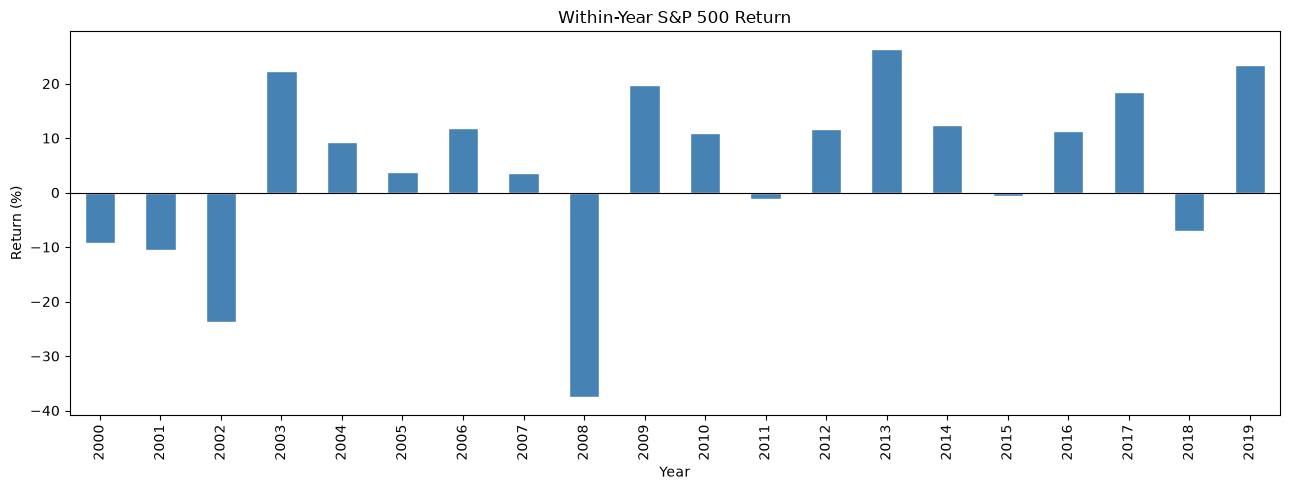

In [8]:
ax = annual_summary["연중 수익률"].mul(100).plot(
    kind="bar", figsize=(13, 5), color="steelblue", edgecolor="white"
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Within-Year S&P 500 Return")
ax.set_xlabel("Year")
ax.set_ylabel("Return (%)")
plt.tight_layout()
plt.show()

## 7. 월별 종가 및 수익률

각 월의 마지막 관측 종가와 그 전월 말 종가 대비 수익률을 확인합니다. 데이터가 존재하는 월만 포함되며, 첫 달의 수익률은 이전 달 데이터가 없어 결측입니다.

월말 종가 기준 월 수익률 상위 5개월:


,월말 종가,전월 대비 수익률
월,,
2011-10,1253.3,0.1077
2000-03,1498.6,0.0968
2009-04,872.8,0.0939
2010-09,1141.2,0.0876
2002-10,885.8,0.0865


월말 종가 기준 월 수익률 하위 5개월:


,월말 종가,전월 대비 수익률
월,,
2008-10,968.8,-0.1694
2002-09,815.3,-0.11
2009-02,735.1,-0.1099
2001-02,1239.9,-0.0923
2018-12,2506.8,-0.0918


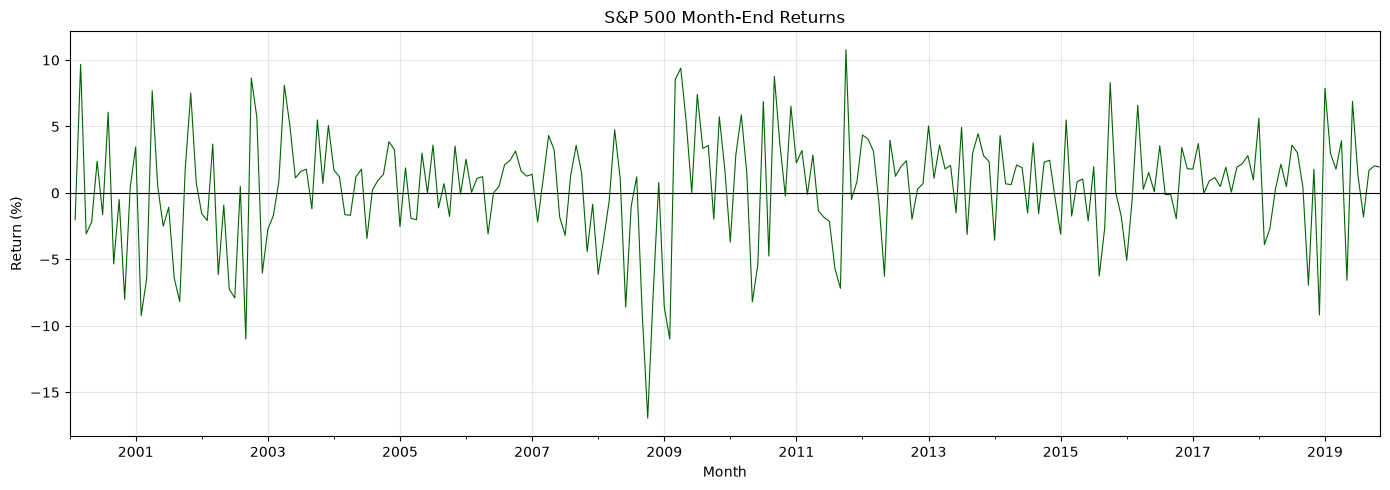

In [9]:
monthly_close = (
    df.assign(월=df["날짜"].dt.to_period("M"))
    .groupby("월")["종가"]
    .last()
)
monthly_summary = monthly_close.to_frame("월말 종가")
monthly_summary["전월 대비 수익률"] = monthly_summary["월말 종가"].pct_change(fill_method=None)

print("월말 종가 기준 월 수익률 상위 5개월:")
display(monthly_summary.nlargest(5, "전월 대비 수익률").round(4))
print("월말 종가 기준 월 수익률 하위 5개월:")
display(monthly_summary.nsmallest(5, "전월 대비 수익률").round(4))

monthly_summary["전월 대비 수익률"].mul(100).plot(figsize=(14, 5), color="darkgreen", linewidth=0.8)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("S&P 500 Month-End Returns")
plt.xlabel("Month")
plt.ylabel("Return (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 해석 시 유의사항

- 원본에 거래량 값이 없어 거래량 기반 분석은 수행하지 않았습니다.
- 데이터는 2019년 11월 14일에 끝나므로 2019년 마지막 두 달의 추세를 나타내지 않습니다.
- 연중 수익률은 해당 연도의 첫 관측 종가와 마지막 관측 종가 사이의 변화이며, 배당을 포함한 총수익률이 아닙니다.
- 연율화 변동성의 252 거래일 가정은 근사치입니다.